1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

2. Uploading and Loading the dataset

In [ ]:
df = pd.read_csv("/content/fertilizer_recommendation_dataset__2__noisy.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (3100, 12)


,Temperature,Moisture,Rainfall,PH,Nitrogen,Phosphorous,Potassium,Carbon,Soil,Crop,Fertilizer,Remark
0,50.246626,0.719447,206.257801,6.221906,66.682875,75.827976,95.472430,0.509303,Loamy Soil,rice,Compost,Enhances organic matter and improves soil stru...
1,21.818755,0.718439,303.142717,7.131341,71.516130,163.104621,148.307070,1.225821,Loamy Soil,rice,Balanced NPK Fertilizer,"Provides a balanced mix of nitrogen, phosphoru..."
2,22.900860,0.681577,259.801181,7.348401,75.830802,62.103522,80.968651,1.819554,Peaty Soil,rice,Water Retaining Fertilizer,Improves water retention in dry soils. Prefer ...
3,25.993514,0.753066,214.391771,6.927501,78.287230,150.227976,154.014592,1.512504,Loamy Soil,rice,Balanced NPK Fertilizer,"Provides a balanced mix of nitrogen, phosphoru..."
4,20.945522,0.729516,264.803799,7.569270,71.756057,68.173816,97.060956,1.788897,Peaty Soil,rice,Organic Fertilizer,"Enhances fertility naturally, ideal for peaty ..."


3. Understand the Dataset

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['Temperature', 'Moisture', 'Rainfall', 'PH', 'Nitrogen', 'Phosphorous', 'Potassium', 'Carbon', 'Soil', 'Crop', 'Fertilizer', 'Remark']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3100 entries, 0 to 3099
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  3100 non-null   float64
 1   Moisture     3100 non-null   float64
 2   Rainfall     3100 non-null   float64
 3   PH           3100 non-null   float64
 4   Nitrogen     3100 non-null   float64
 5   Phosphorous  3100 non-null   float64
 6   Potassium    3100 non-null   float64
 7   Carbon       3100 non-null   float64
 8   Soil         3100 non-null   object 
 9   Crop         3100 non-null   object 
 10  Fertilizer   3100 non-null   object 
 11  Remark       3100 non-null   object 
dtypes: float64(8), object(4)
memory usage: 290.8+ KB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Temperature,3100.0,NaN,NaN,NaN,27.271821,9.11,4.011486,22.42021,26.127903,29.972886,56.653592
Moisture,3100.0,NaN,NaN,NaN,0.600655,0.144834,0.227436,0.493063,0.600093,0.708162,0.972361
Rainfall,3100.0,NaN,NaN,NaN,112.98127,73.118395,0.0,61.396534,97.014937,147.016644,411.955947
PH,3100.0,NaN,NaN,NaN,6.379537,0.95845,3.448974,5.858704,6.335562,6.90309,9.562341
Nitrogen,3100.0,NaN,NaN,NaN,61.282725,10.180231,35.527718,54.885455,59.468087,65.903007,98.581039
Phosphorous,3100.0,NaN,NaN,NaN,70.505208,40.106737,0.0,43.218465,58.318749,85.888812,177.314481
Potassium,3100.0,NaN,NaN,NaN,70.192837,34.228206,0.0,49.804983,58.823401,76.21634,161.067982
Carbon,3100.0,NaN,NaN,NaN,1.481565,0.679858,0.0,0.95161,1.458582,2.004261,3.241984
Soil,3100,5,Acidic Soil,1519,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,3100,31,rice,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN


4. Check Data Quality

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nNumber of unique values:")
print(df.nunique())


Missing values per column:
Temperature    0
Moisture       0
Rainfall       0
PH             0
Nitrogen       0
Phosphorous    0
Potassium      0
Carbon         0
Soil           0
Crop           0
Fertilizer     0
Remark         0
dtype: int64

Exact duplicate rows: 0

Number of unique values:
Temperature    3069
Moisture       3029
Rainfall       3026
PH             3100
Nitrogen       3060
Phosphorous    2988
Potassium      3025
Carbon         2978
Soil              5
Crop             31
Fertilizer       10
Remark           10
dtype: int64


5. Explore Fertilizer Labels

Number of fertilizer classes: 10

Fertilizer counts:
Fertilizer
DAP                           1030
Water Retaining Fertilizer     663
Compost                        369
Muriate of Potash              323
Lime                           181
Urea                           162
Balanced NPK Fertilizer        157
Organic Fertilizer             108
Gypsum                          65
General Purpose Fertilizer      42
Name: count, dtype: int64


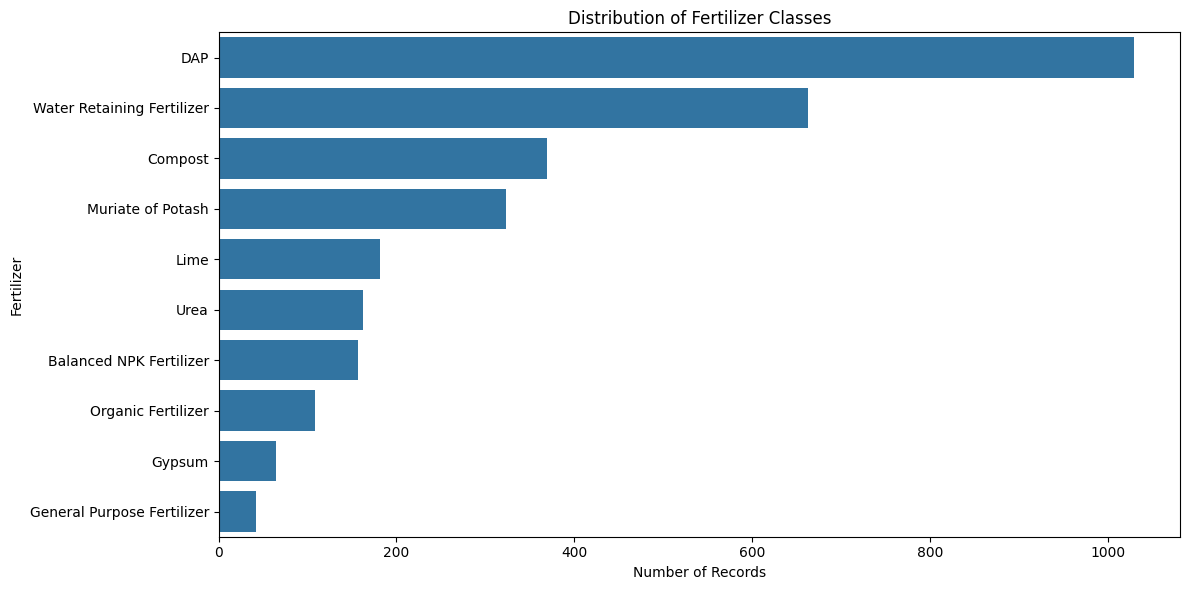

In [ ]:
print("Number of fertilizer classes:",
      df["Fertilizer"].nunique())

print("\nFertilizer counts:")
print(df["Fertilizer"].value_counts())

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Fertilizer",
    order=df["Fertilizer"].value_counts().index
)

plt.title("Distribution of Fertilizer Classes")
plt.xlabel("Number of Records")
plt.ylabel("Fertilizer")
plt.tight_layout()
plt.show()

6. Explore Fertilizer Recommendation By Crop

Number of crop types: 31


Fertilizer,Balanced NPK Fertilizer,Compost,DAP,General Purpose Fertilizer,Gypsum,Lime,Muriate of Potash,Organic Fertilizer,Urea,Water Retaining Fertilizer
Crop,,,,,,,,,,
Adzuki Beans,9,12,40,4,2,3,8,2,3,17
Black gram,21,20,3,1,3,2,4,4,4,38
Chickpea,4,3,62,0,1,1,2,0,20,7
Coconut,0,15,24,2,1,22,5,6,3,22
Coffee,6,26,10,3,0,6,3,0,1,45
Cotton,6,18,10,1,5,4,11,5,1,39
Ground Nut,0,16,29,0,3,7,10,8,5,22
Jute,12,29,7,2,0,4,2,2,3,39
Kidney Beans,0,0,90,0,0,1,2,0,7,0


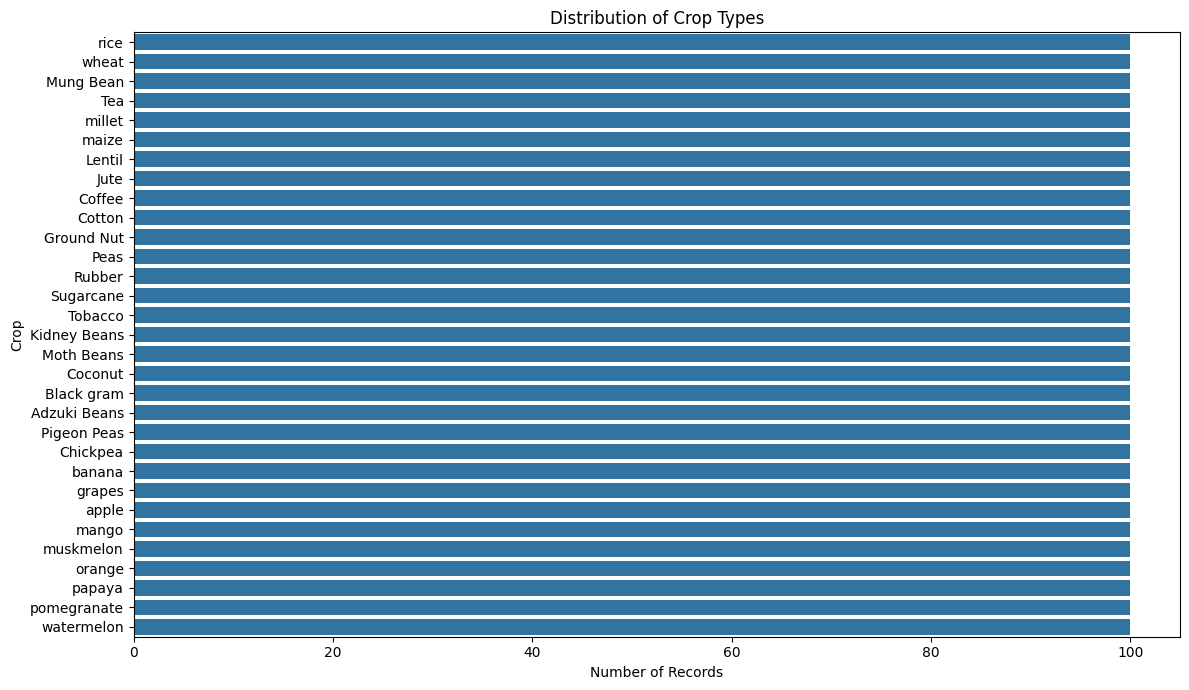

In [ ]:
print("Number of crop types:", df["Crop"].nunique())

display(
    pd.crosstab(df["Crop"], df["Fertilizer"])
)

plt.figure(figsize=(12, 7))

sns.countplot(
    data=df,
    y="Crop",
    order=df["Crop"].value_counts().index
)

plt.title("Distribution of Crop Types")
plt.xlabel("Number of Records")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

7. Define features and Targets

In [ ]:

# Define features and target
feature_columns = [
    "Temperature",
    "Moisture",
    "Rainfall",
    "PH",
    "Nitrogen",
    "Phosphorous",
    "Potassium",
    "Carbon",
    "Soil",
    "Crop"
]

# Create a copy of the original dataset
df_clean = df.copy()

# Treat negative measurements as invalid/missing
invalid_columns = [
    "Rainfall",
    "Phosphorous",
    "Potassium",
    "Carbon"
]

print("Negative values detected before cleaning:")
for col in invalid_columns:
    count = (df_clean[col] < 0).sum()
    print(f"{col}: {count}")

    df_clean.loc[df_clean[col] < 0, col] = np.nan

# Create features and target from the cleaned dataset
X = df_clean[feature_columns].copy()
y = df_clean["Fertilizer"].copy()

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values after cleaning:")
print(X[invalid_columns].isnull().sum())

print("\nTarget classes:")
print(sorted(y.unique()))


Negative values detected before cleaning:
Rainfall: 0
Phosphorous: 0
Potassium: 0
Carbon: 0

Input shape: (3100, 10)
Target shape: (3100,)

Missing values after cleaning:
Rainfall       0
Phosphorous    0
Potassium      0
Carbon         0
dtype: int64

Target classes:
['Balanced NPK Fertilizer', 'Compost', 'DAP', 'General Purpose Fertilizer', 'Gypsum', 'Lime', 'Muriate of Potash', 'Organic Fertilizer', 'Urea', 'Water Retaining Fertilizer']


8. Split the Data

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

Training records: 2480
Testing records: 620

Training target distribution:
Fertilizer
DAP                           824
Water Retaining Fertilizer    530
Compost                       295
Muriate of Potash             258
Lime                          145
Urea                          130
Balanced NPK Fertilizer       126
Organic Fertilizer             86
Gypsum                         52
General Purpose Fertilizer     34
Name: count, dtype: int64


9. Build the preprocessing pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

numeric_features = [
    "Temperature",
    "Moisture",
    "Rainfall",
    "PH",
    "Nitrogen",
    "Phosphorous",
    "Potassium",
    "Carbon"
]

categorical_features = [
    "Soil",
    "Crop"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

fertilizer_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

print("Preprocessing and model pipeline created.")

Preprocessing and model pipeline created.


Train the model

In [ ]:
fertilizer_model.fit(X_train, y_train)

print("Fertilizer recommendation model trained successfully!")

Fertilizer recommendation model trained successfully!


Evaluate the Model

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

y_pred = fertilizer_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.4f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Test accuracy: 0.9113
Test accuracy: 91.13%

Classification report:
                            precision    recall  f1-score   support

   Balanced NPK Fertilizer       0.88      0.97      0.92        31
                   Compost       0.89      0.89      0.89        74
                       DAP       0.94      0.97      0.96       206
General Purpose Fertilizer       1.00      0.75      0.86         8
                    Gypsum       1.00      0.54      0.70        13
                      Lime       0.77      0.83      0.80        36
         Muriate of Potash       0.94      0.91      0.92        65
        Organic Fertilizer       0.74      0.64      0.68        22
                      Urea       0.90      0.84      0.87        32
Water Retaining Fertilizer       0.93      0.95      0.94       133

                  accuracy                           0.91       620
                 macro avg       0.90      0.83      0.85       620
              weighted avg       0.91      0.9

Visualize The confusion matrix

<Figure size 1200x1000 with 0 Axes>

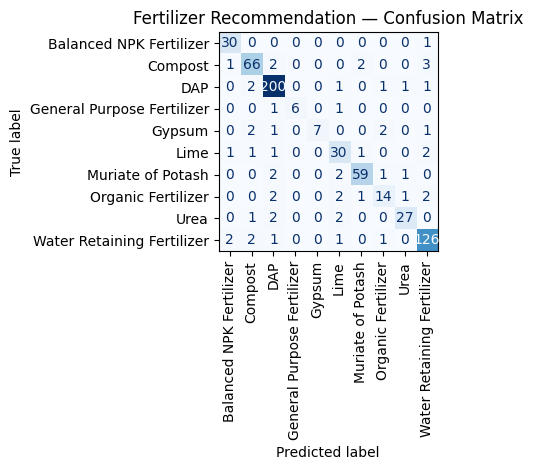

In [ ]:
plt.figure(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("Fertilizer Recommendation — Confusion Matrix")
plt.tight_layout()
plt.show()

test New Recommendation

In [ ]:
new_sample = pd.DataFrame([{
    "Temperature": 25.0,
    "Moisture": 0.50,
    "Rainfall": 100.0,
    "PH": 6.5,
    "Nitrogen": 50.0,
    "Phosphorous": 40.0,
    "Potassium": 40.0,
    "Carbon": 1.5,
    "Soil": "Loamy Soil",
    "Crop": "rice"
}])

predicted_fertilizer = fertilizer_model.predict(new_sample)[0]

probabilities = fertilizer_model.predict_proba(new_sample)[0]

class_probabilities = pd.DataFrame({
    "Fertilizer": fertilizer_model.classes_,
    "Model Probability": probabilities
}).sort_values(
    by="Model Probability",
    ascending=False
)

print("Predicted fertilizer category:", predicted_fertilizer)

print("\nTop 5 model predictions:")
display(class_probabilities.head(5))

Predicted fertilizer category: DAP

Top 5 model predictions:


,Fertilizer,Model Probability
2,DAP,0.466667
8,Urea,0.353333
6,Muriate of Potash,0.090000
9,Water Retaining Fertilizer,0.060000
7,Organic Fertilizer,0.010000


Save the trained Model

In [ ]:
import joblib

model_filename = "agripredict_fertilizer_model.joblib"

joblib.dump(fertilizer_model, model_filename)

print("Model saved as:", model_filename)

Model saved as: agripredict_fertilizer_model.joblib


Load and Reuse the Saved Model

In [ ]:
import joblib

loaded_model = joblib.load(
    "agripredict_fertilizer_model.joblib"
)

test_prediction = loaded_model.predict(new_sample)

print("Prediction from saved model:", test_prediction[0])

Prediction from saved model: DAP


Enter Field Data And Predict

In [ ]:
import pandas as pd

new_field = pd.DataFrame([{
    "Temperature": 25.0,
    "Moisture": 0.50,
    "Rainfall": 100.0,
    "PH": 6.5,
    "Nitrogen": 50.0,
    "Phosphorous": 40.0,
    "Potassium": 40.0,
    "Carbon": 1.5,
    "Soil": "Loamy Soil",
    "Crop": "rice"
}])

prediction = fertilizer_model.predict(new_field)

print("Recommended fertilizer:", prediction[0])

Recommended fertilizer: DAP


In [ ]:
!pip install -q shap
from export_utils import export_module
remarks = df.drop_duplicates("Fertilizer").set_index("Fertilizer")["Remark"].to_dict()
export_module("fertilizer", fertilizer_model, X_train, y_train, X_test, y_test,
              trained_on="fertilizer_recommendation_dataset__2__noisy.csv", remarks=remarks)
!zip -rq fertilizer_export.zip models/fertilizer
from google.colab import files
files.download("fertilizer_export.zip")

dashboard config block: {"metrics": {"accuracy": 0.9113, "top3": 0.9726, "macro_f1": 0.8542}, "importance": {"Phosphorus": 0.2101, "Soil pH": 0.1259, "Soil": 0.1228, "Potassium": 0.1194, "Soil carbon": 0.1186, "Soil moisture": 0.1156, "Nitrogen": 0.0863, "Crop": 0.0485, "Rainfall": 0.0298, "Temperature": 0.0231}}
Exported fertilizer -> models/fertilizer  |  {'accuracy': 0.9113, 'macro_f1': 0.8542, 'top3_accuracy': 0.9726, 'n_train': 2480, 'n_test': 620}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
print(json.load(open("models/fertilizer/metadata.json"))["importance"][:3])

[{'feature': 'Phosphorous', 'importance': 0.2101}, {'feature': 'PH', 'importance': 0.1259}, {'feature': 'Soil', 'importance': 0.1228}]
